In [1]:
import pickle
import xarray as xr
import xesmf as xe
import numpy as np
import warnings
import xarray as xr
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy
from mpl_toolkits.axes_grid1 import make_axes_locatable
import sys
import os
import matplotlib.colors as mcolors
import matplotlib
warnings.filterwarnings("ignore", category=UserWarning, module="xesmf")

# Tropical cyclone filter of the contributions and densities (see ETC_tools.py): None (all
# cyclones), 'phase' or 'storm'. The percentiles do not depend on it.
tc_filter = 'phase'
tc_tag = {None: '', 'phase': '_noTC', 'storm': '_noTCstorm'}[tc_filter]

/cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/MPI/gcc12/openmpi4/esmf/8.8.0/lib/python3.11/site-packages/esmpy/interface/loadESMF.py:94: VersionWarning: ESMF installation version 8.8.0, ESMPy version 8.8.0b0
  warnings.warn("ESMF installation version {}, ESMPy version {}".format(


## Regrillage des totaux/comptages de la précipitation/vent des ETCs et des centiles des simulations régionales sur la grille de ERA5, afin de pouvoir les comparer directement

### Méthode correcte
Les totaux (total_) sont regrillés de manière conservative, car ils dépendent de la taille du point de grille (plus il est grand plus le total est grand).

Les comptages (count_) sont regrillés avec le voisin le plus proche, car ils représentent des incréments avec un cyclone dans les 1000km.

Pour garder que le domaine du CRCM6 dans les sorties, on multiplie par le mask_tgt qui a été crée avec la méthode conservative. Il y'a donc des nombres décimaux qui représentent la proportion du recouvrement partiel d'un point de grille de la grille d'origine sur la grille cible. C'est pour cela qu'on a des comptages décimaux.

#### Création des grid

In [2]:
def compute_cell_area_2d(lat, lon):
    """Approximation sphérique pour grille 2D Rotated Pole"""
    R = 6371000.0
    dlat = np.gradient(lat, axis=0)
    dlon = np.gradient(lon, axis=1)
    lat_rad = np.deg2rad(lat)
    dlat_rad = np.deg2rad(dlat)
    dlon_rad = np.deg2rad(dlon)
    area = np.abs(R**2 * dlat_rad * dlon_rad * np.cos(lat_rad))
    return xr.DataArray(area, coords=lat.coords, dims=lat.dims, name="cell_area")

def compute_bounds_1d(arr):
    """Compute cell bounds for a 1D coordinate array."""
    b = 0.5*(arr[1:] + arr[:-1])
    # extrapolate at edges
    b = np.concatenate(([arr[0] - (b[0]-arr[0])], b, [arr[-1] + (arr[-1]-b[-1])]))
    return b

def compute_bounds_2d(lat, lon):
    """
    Compute 2D cell boundaries from 2D lat/lon center grids.
    Works for regular, irregular and rotated-pole grids.
    Dateline handling stays exactly as in original code.
    """
    M, N = lat.shape

    lat_b = np.zeros((M+1, N+1))
    lon_b = np.zeros((M+1, N+1))

    # --- Utility: circular mean for longitudes ---
    def mean_lon(lons):
        lons_rad = np.deg2rad(lons)
        sin_m = np.mean(np.sin(lons_rad))
        cos_m = np.mean(np.cos(lons_rad))
        return np.rad2deg(np.arctan2(sin_m, cos_m))

    # ============================================================
    # 1) INTERNAL CORNERS (unchanged)
    # ============================================================
    for i in range(1, M):
        for j in range(1, N):
            lat_b[i,j] = np.mean([
                lat[i-1,j-1], lat[i,j-1],
                lat[i-1,j],   lat[i,j]
            ])
            lon_b[i,j] = mean_lon([
                lon[i-1,j-1], lon[i,j-1],
                lon[i-1,j],   lon[i,j]
            ])

    # ============================================================
    # 2) INTERNAL BORDER CORNERS (unchanged)
    # ============================================================
    # Top/bottom
    for j in range(1, N):
        lat_b[0,j] = np.mean([lat[0,j-1], lat[0,j], lat[1,j-1], lat[1,j]])
        lat_b[-1,j] = np.mean([lat[-1,j-1], lat[-1,j], lat[-2,j-1], lat[-2,j]])

        lon_b[0,j] = mean_lon([lon[0,j-1], lon[0,j], lon[1,j-1], lon[1,j]])
        lon_b[-1,j] = mean_lon([lon[-1,j-1], lon[-1,j], lon[-2,j-1], lon[-2,j]])

    # Left/right
    for i in range(1, M):
        lat_b[i,0] = np.mean([lat[i-1,0], lat[i,0], lat[i-1,1], lat[i,1]])
        lat_b[i,-1] = np.mean([lat[i-1,-1], lat[i,-1], lat[i-1,-2], lat[i,-2]])

        lon_b[i,0] = mean_lon([lon[i-1,0], lon[i,0], lon[i-1,1], lon[i,1]])
        lon_b[i,-1] = mean_lon([lon[i-1,-1], lon[i,-1], lon[i-1,-2], lon[i,-2]])

    # ============================================================
    # 3) ADD TRUE OUTER BOUNDARIES
    # ============================================================

    # Top external boundary (row -1/2)
    lat_b[0, :] = 2*lat_b[1, :] - lat_b[2, :]
    lon_b[0, :] = 2*lon_b[1, :] - lon_b[2, :]

    # Bottom external boundary (row M+1/2)
    lat_b[-1, :] = 2*lat_b[-2, :] - lat_b[-3, :]
    lon_b[-1, :] = 2*lon_b[-2, :] - lon_b[-3, :]

    # Left external boundary (col -1/2)
    lat_b[:, 0] = 2*lat_b[:, 1] - lat_b[:, 2]
    lon_b[:, 0] = 2*lon_b[:, 1] - lon_b[:, 2]

    # Right external boundary (col N+1/2)
    lat_b[:, -1] = 2*lat_b[:, -2] - lat_b[:, -3]
    lon_b[:, -1] = 2*lon_b[:, -2] - lon_b[:, -3]

    return lat_b, lon_b

In [3]:
# -------------------------------
# Chargement des données
# -------------------------------
# file_path = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/CONTRIB/contribution_ETCs_1000hPa_future_percentile{tc_tag}.pkl'
file_path = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/CONTRIB/contribution_ETCs_1000hPa{tc_tag}.pkl'
with open(file_path, 'rb') as f:
    merged_all = pickle.load(f)

FileNotFoundError: [Errno 2] No such file or directory: '/home/vdemeyer/projects/rrg-gachon/vdemeyer/CONTRIB/contribution_ETCs_1000hPa.pkl'

In [4]:
# -------------------------------
# Grille cible (ERA5)
# -------------------------------
target_grid = merged_all['total_ext_EETCs_total']['ERA5']
lat_tgt = target_grid['latitude'].values
lon_tgt = target_grid['longitude'].values
# lat_b_tgt = compute_bounds_1d(lat_tgt)
# lon_b_tgt = compute_bounds_1d(lon_tgt)

lat2d_tgt, lon2d_tgt = np.meshgrid(lat_tgt, lon_tgt, indexing='ij')

lat_b_tgt, lon_b_tgt = compute_bounds_2d(lat2d_tgt, lon2d_tgt)

grid_tgt = xr.Dataset(
    coords={
        "latitude": ("latitude", lat_tgt),
        "longitude": ("longitude", lon_tgt),
        'latitude_b': ('latitude_b', np.arange(len(lat_tgt)+1)),
        'longitude_b': ('longitude_b', np.arange(len(lon_tgt)+1)),
        'lat': (('latitude','longitude'), lat2d_tgt),
        'lon': (('latitude','longitude'), lon2d_tgt),
        'lat_b': (('latitude_b','longitude_b'), lat_b_tgt),
        'lon_b': (('latitude_b','longitude_b'), lon_b_tgt)
    }
)

# area_target = compute_cell_area_2d(grid_tgt['lat'], grid_tgt['lon'])

In [5]:
# -------------------------------
# Grille source (UBB)
# -------------------------------
original_grid = merged_all['total_ext_EETCs_total']['UBB']
rlat_ori = original_grid['rlat'].values
rlon_ori = original_grid['rlon'].values

lat_ori = original_grid["lat"].values
lon_ori = original_grid["lon"].values

lat_b_ori, lon_b_ori = compute_bounds_2d(lat_ori, lon_ori)

grid_src = xr.Dataset(
    coords={
        'rlat': ('rlat', rlat_ori),
        'rlon': ('rlon', rlon_ori),
        'rlat_b': ('rlat_b', np.arange(len(rlat_ori)+1)),  # <- ici
        'rlon_b': ('rlon_b', np.arange(len(rlon_ori)+1)),  # <- ici
        'lat': (('rlat','rlon'), lat_ori),
        'lon': (('rlat','rlon'), lon_ori),
        'lat_b': (('rlat_b','rlon_b'), lat_b_ori),
        'lon_b': (('rlat_b','rlon_b'), lon_b_ori)
    }
)

# area_src = compute_cell_area_2d(original_grid['lat'], original_grid['lon'])

#### Plot check of ERA5 grid

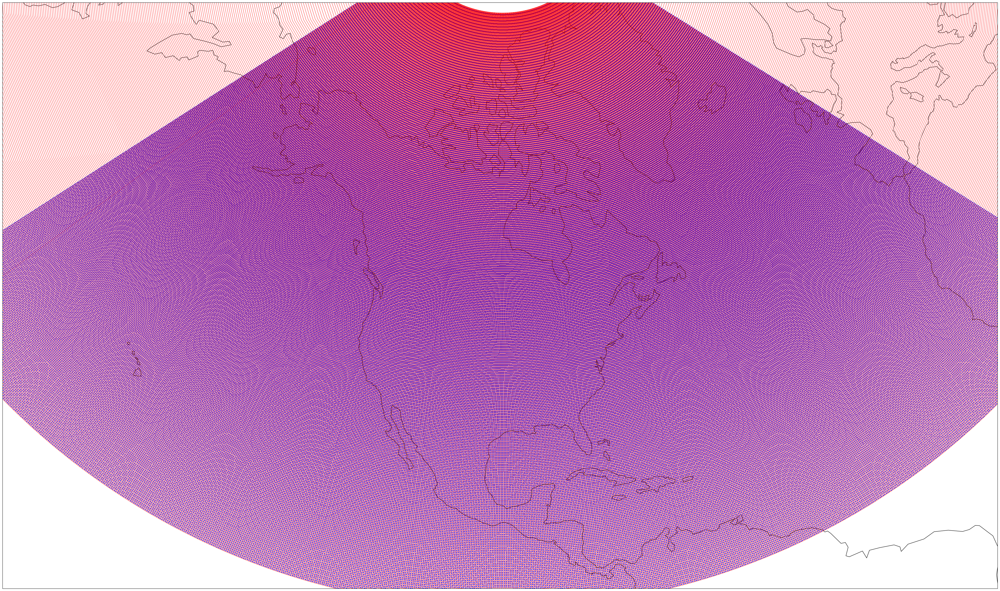

In [18]:
proj = ccrs.PlateCarree()
plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)

fig, ax = plt.subplots(subplot_kw={'projection': plotcrs},
                       figsize=(40, 32), tight_layout = {'pad': 0})

ax.set_extent([-170, -21, 82, 7], crs=proj)

ax.coastlines()

# tracer centres des cellules
ax.scatter(grid_tgt["lon"].values, grid_tgt["lat"].values, s=4, color='blue', transform=proj)

# tracer les bounds → lignes horizontales
for i in range(grid_tgt["lat_b"].values.shape[0]):
    ax.plot(grid_tgt["lon_b"].values[i, :], grid_tgt["lat_b"].values[i, :], color='red', alpha=1, linewidth=0.7, transform=proj)

# tracer les bounds → lignes verticales
for j in range(lon_b_tgt.shape[1]):
    ax.plot(grid_tgt["lon_b"].values[:, j], grid_tgt["lat_b"].values[:, j], color='red', alpha=1, linewidth=0.7, transform=proj)

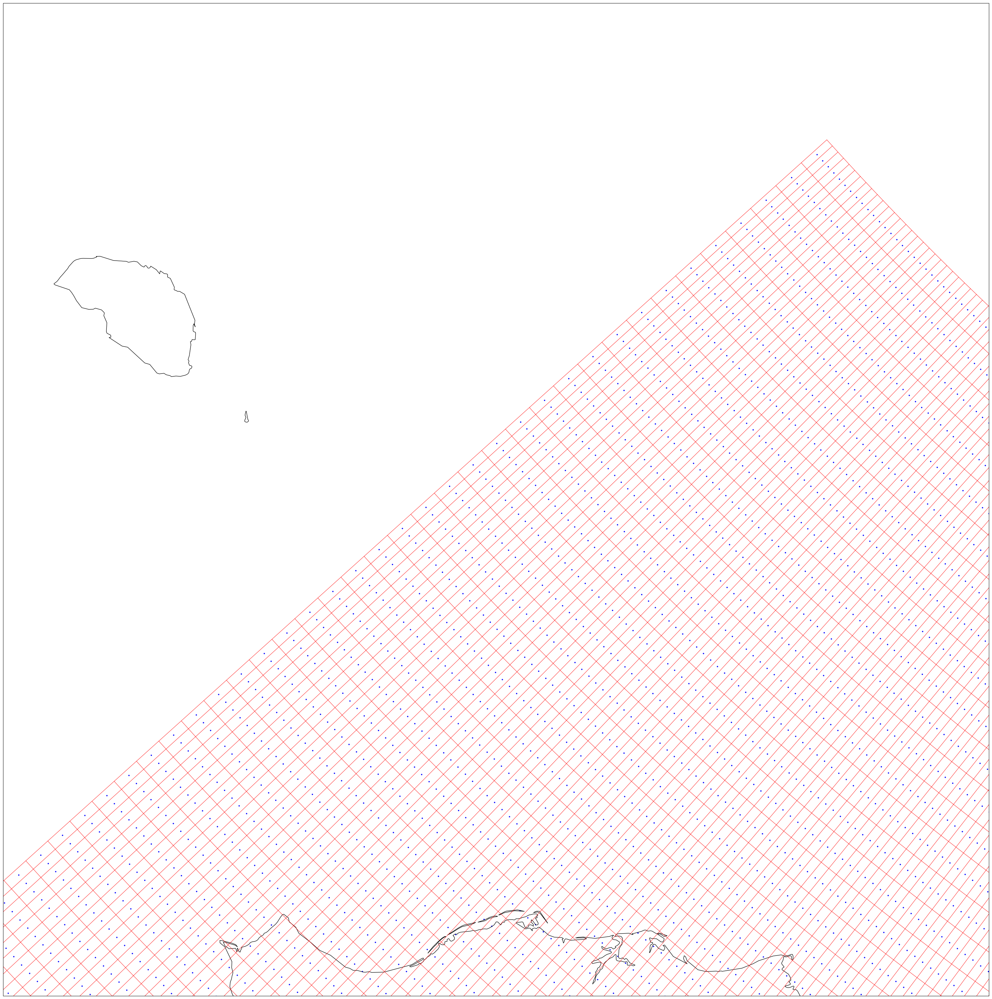

In [281]:
plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)

fig, ax = plt.subplots(subplot_kw={'projection': plotcrs},
                       figsize=(40, 32), tight_layout = {'pad': 0})

ax.set_extent([-180, -160, 70, 75], crs=proj)
ax.coastlines()

# tracer centres des cellules
ax.scatter(grid_tgt["lon"].values, grid_tgt["lat"].values, s=4, color='blue', transform=ccrs.PlateCarree())

# tracer les bounds → lignes horizontales
for i in range(grid_tgt["lat_b"].values.shape[0]):
    ax.plot(grid_tgt["lon_b"].values[i, :], grid_tgt["lat_b"].values[i, :], color='red', alpha=1, linewidth=0.7, transform=ccrs.Geodetic())

# tracer les bounds → lignes verticales
for j in range(lon_b_tgt.shape[1]):
    ax.plot(grid_tgt["lon_b"].values[:, j], grid_tgt["lat_b"].values[:, j], color='red', alpha=1, linewidth=0.7, transform=ccrs.Geodetic())

#### Plot check of CRCM6 grid

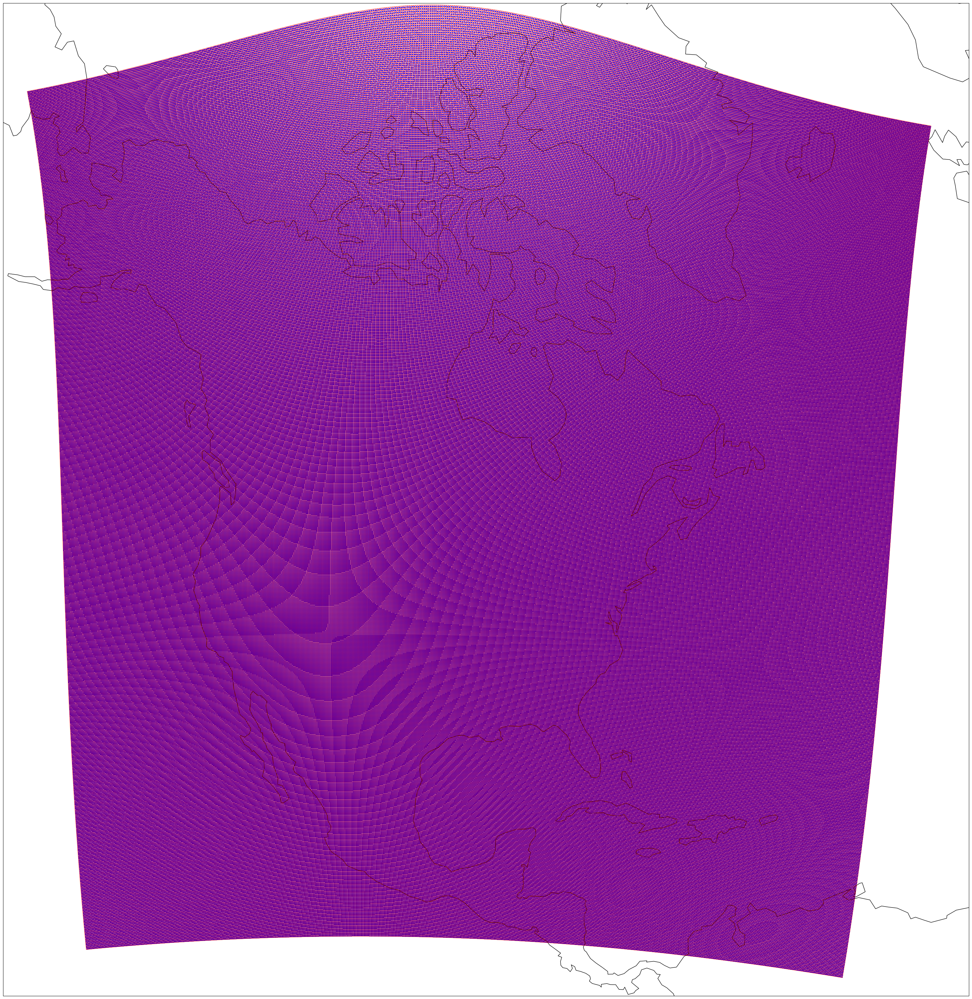

In [283]:
plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)
fig, ax = plt.subplots(subplot_kw={'projection': plotcrs},
                       figsize=(40, 32), tight_layout = {'pad': 0})

ax.set_extent([-130, -53, 84, 8], crs=ccrs.PlateCarree())
ax.coastlines()

# tracer centres des cellules
ax.scatter(grid_src["lon"].values, grid_src["lat"].values, s=4, color='blue', transform=ccrs.Geodetic())

# tracer les bounds → lignes horizontales
for i in range(grid_src["lat_b"].values.shape[0]):
    ax.plot(grid_src["lon_b"].values[i, :], grid_src["lat_b"].values[i, :], color='red', alpha=1, linewidth=0.7, transform=ccrs.Geodetic())

# tracer les bounds → lignes verticales
for j in range(lon_b_src.shape[1]):
    ax.plot(grid_src["lon_b"].values[:, j], grid_src["lat_b"].values[:, j], color='red', alpha=1, linewidth=0.7, transform=ccrs.Geodetic())

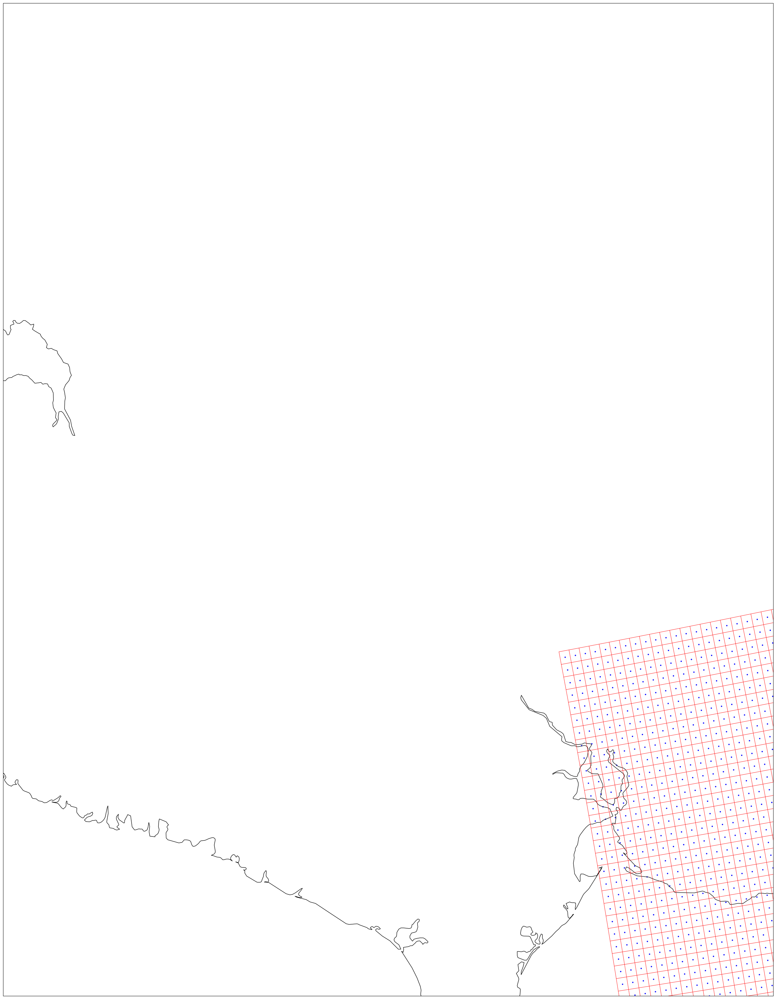

In [284]:
plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)
fig, ax = plt.subplots(subplot_kw={'projection': plotcrs},
                       figsize=(40, 32), tight_layout = {'pad': 0})

# ax.set_extent([157, 150, 72, 35], crs=ccrs.PlateCarree())
# ax.set_extent([170, 160, 58, 70], crs=ccrs.PlateCarree())
ax.set_extent([179, 160, 63, 66], crs=ccrs.PlateCarree())
ax.coastlines()

# tracer centres des cellules
ax.scatter(grid_src["lon"].values, grid_src["lat"].values, s=4, color='blue', transform=ccrs.Geodetic())

# tracer les bounds → lignes horizontales
for i in range(grid_src["lat_b"].values.shape[0]):
    ax.plot(grid_src["lon_b"].values[i, :], grid_src["lat_b"].values[i, :], color='red', alpha=1, linewidth=0.7, transform=ccrs.Geodetic())
# for i in range(650,656):
    # ax.plot(grid_src["lon_b"].values[i, :], grid_src["lat_b"].values[i, :], color='red', alpha=1, linewidth=0.7, transform=ccrs.Geodetic())
# tracer les bounds → lignes verticales
for j in range(lon_b_src.shape[1]):
    ax.plot(grid_src["lon_b"].values[:, j], grid_src["lat_b"].values[:, j], color='red', alpha=1, linewidth=0.7, transform=ccrs.Geodetic())

#### Construction des regridder

In [6]:
# -------------------------------
# Regrillage conservatif - Pour les variables total_*
# -------------------------------

regridder_conservative = xe.Regridder(
    grid_src, grid_tgt,
    method='conservative',
    periodic=True,
    ignore_degenerate=True
)

In [7]:
# -------------------------------
# Regrillage nearest - Pour les variables count_*
# -------------------------------

regridder_nearest = xe.Regridder(
    grid_src,
    grid_tgt,
    method='nearest_s2d',
    # periodic=True,
    # ignore_degenerate=True
)

#### Test

In [30]:
data = merged_all['total_ext_EETCs_total']['UBB']
mask_src = xr.where(np.isfinite(data), 1.0, np.nan)
mask_tgt = regridder_conservative(mask_src)
# density = data / area_src
# density_tgt = regridder(density)
# data_regridded = density_tgt * area_target
data_regridded = regridder_conservative(data)
data_regridded = data_regridded * mask_tgt

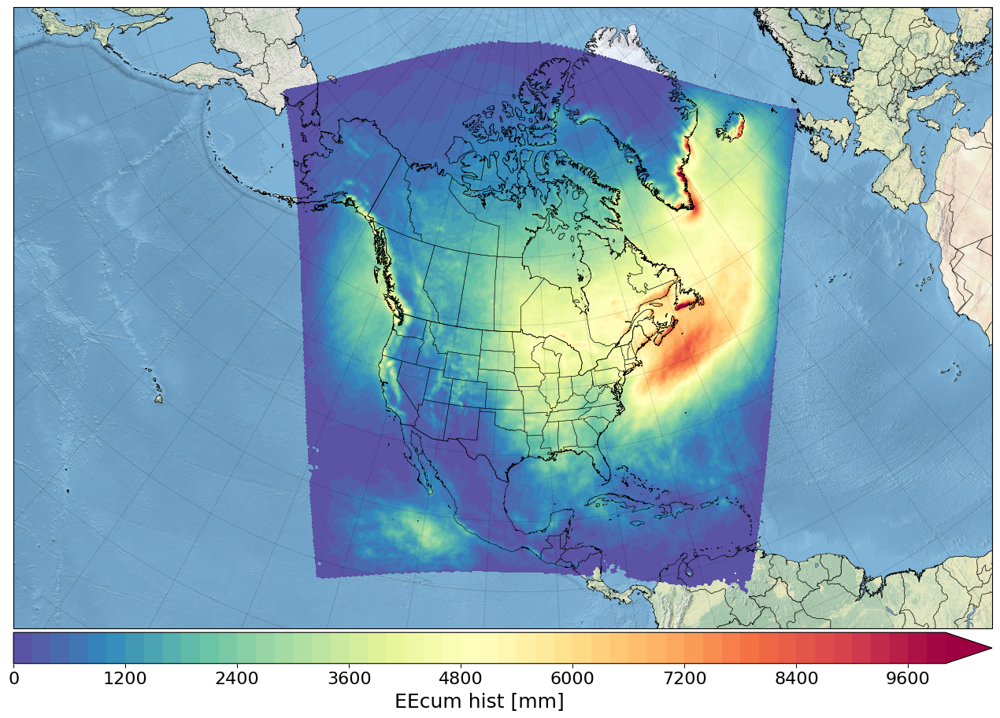

In [31]:
to_plot = data_regridded.sel(quantile=0.99, variable='pr')

plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)

fig, ax = plt.subplots(subplot_kw={'projection': plotcrs},
                       figsize=(12.5,12.5), tight_layout = {'pad': 0})

divider = make_axes_locatable(ax)
cax = divider.append_axes("bottom", size="5%", pad=0.05, axes_class=plt.Axes)

# ax.set_extent([-130, -53, 84, 8], crs=ccrs.PlateCarree())
ax.set_extent([-170, -27, 85, 5], crs=ccrs.PlateCarree())

borders = cartopy.feature.NaturalEarthFeature(category='cultural', name='admin_0_boundary_lines_land', scale='50m', facecolor='none')
states_provinces = cartopy.feature.NaturalEarthFeature(category='cultural', name='admin_1_states_provinces', scale='50m', facecolor='none')
lakes = cartopy.feature.NaturalEarthFeature(category='physical', name='lakes', scale='50m', facecolor='#72a2c7')
img = plt.imread('/home/vdemeyer/TOOLS/NE1_50M_SR_W.tif')
ax.add_feature(borders, linewidth=0.5, edgecolor='black', zorder=2)
ax.add_feature(states_provinces, edgecolor='black', linewidth=0.3)
ax.add_feature(lakes, zorder=1, linewidth=0.2, edgecolor='black')
ax.coastlines(resolution='10m', linewidth=0.4, color='black')
ax.gridlines(linewidth=0.5, linestyle='--', color='k', alpha=0.25, xlocs=range(-180,180,10), ylocs=range(-90,90,10))
ax.imshow(img, origin='upper', extent=(-180, 180, -90, 90), transform=ccrs.PlateCarree())

vmin = 0
vmax = 10000
step = 200
levels = np.arange(vmin, vmax + step, step)
cmap = plt.get_cmap('Spectral_r')

sc = ax.contourf(to_plot.longitude, to_plot.latitude, to_plot.where(to_plot>0),
                   transform=ccrs.PlateCarree(),
                   levels=levels,
                   cmap='Spectral_r',
                   extend='max'
                  )

cb = fig.colorbar(sc, cax=cax, orientation="horizontal", pad=0.02, aspect=40, extend='max')
# cb.ax.set_xticklabels(levels)
cb.ax.tick_params(labelsize=16)
cb.set_label(f'EEcum hist [mm]', fontsize=18)

In [47]:
data = merged_all['count_ext_EETCs_total']['UBB']
mask_src = xr.where(np.isfinite(data), 1.0, np.nan)
mask_tgt = regridder_conservative(mask_src)
# density = data / area_src
# density_tgt = regridder(density)
# data_regridded = density_tgt * area_target
data_regridded = regridder_nearest(data)
data_regridded = data_regridded * mask_tgt
# data_regridded = data_regridded.reset_coords(['lat', 'lon'], drop=True) * mask_tgt

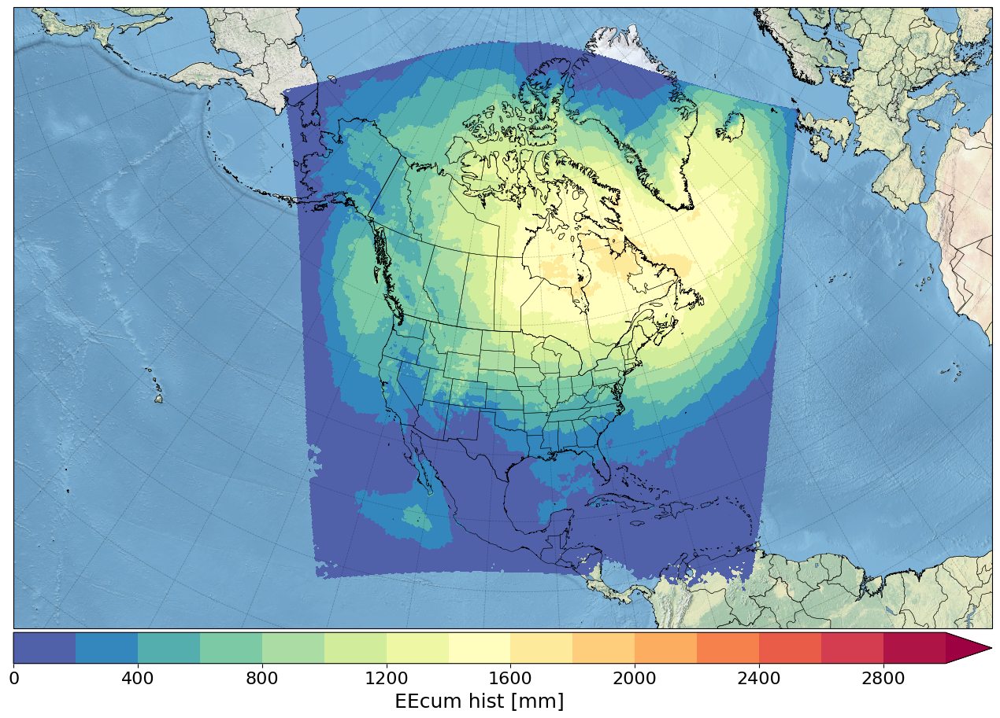

In [48]:
to_plot = data_regridded.sel(quantile=0.99, variable='pr')

plotcrs = ccrs.LambertConformal(central_latitude=45, central_longitude=-95)

fig, ax = plt.subplots(subplot_kw={'projection': plotcrs},
                       figsize=(12.5,12.5), tight_layout = {'pad': 0})

divider = make_axes_locatable(ax)
cax = divider.append_axes("bottom", size="5%", pad=0.05, axes_class=plt.Axes)

# ax.set_extent([-130, -53, 84, 8], crs=ccrs.PlateCarree())
ax.set_extent([-170, -27, 85, 5], crs=ccrs.PlateCarree())

borders = cartopy.feature.NaturalEarthFeature(category='cultural', name='admin_0_boundary_lines_land', scale='50m', facecolor='none')
states_provinces = cartopy.feature.NaturalEarthFeature(category='cultural', name='admin_1_states_provinces', scale='50m', facecolor='none')
lakes = cartopy.feature.NaturalEarthFeature(category='physical', name='lakes', scale='50m', facecolor='#72a2c7')
img = plt.imread('/home/vdemeyer/TOOLS/NE1_50M_SR_W.tif')
ax.add_feature(borders, linewidth=0.5, edgecolor='black', zorder=2)
ax.add_feature(states_provinces, edgecolor='black', linewidth=0.3)
ax.add_feature(lakes, zorder=1, linewidth=0.2, edgecolor='black')
ax.coastlines(resolution='10m', linewidth=0.4, color='black')
ax.gridlines(linewidth=0.5, linestyle='--', color='k', alpha=0.25, xlocs=range(-180,180,10), ylocs=range(-90,90,10))
ax.imshow(img, origin='upper', extent=(-180, 180, -90, 90), transform=ccrs.PlateCarree())

vmin = 0
vmax = 3000
step = 200
levels = np.arange(vmin, vmax + step, step)
cmap = plt.get_cmap('Spectral_r')

sc = ax.contourf(to_plot.longitude, to_plot.latitude, to_plot.where(to_plot>0),
                   transform=ccrs.PlateCarree(),
                   levels=levels,
                   cmap='Spectral_r',
                   extend='max'
                  )

cb = fig.colorbar(sc, cax=cax, orientation="horizontal", pad=0.02, aspect=40, extend='max')
# cb.ax.set_xticklabels(levels)
cb.ax.tick_params(labelsize=16)
cb.set_label(f'EEcum hist [mm]', fontsize=18)

#### Regridding

In [8]:
simulations = ['ERA5', 'UBB', 'UBD', 'UBE', 'UBF', 'UBG', 'UBH', 'UBI']
merged_all_regridded = {}

mask_src = xr.where(np.isfinite(merged_all['total_total']['UBB'].sel(variable='ws')), 1.0, np.nan)
mask_tgt = regridder_conservative(mask_src)
mask_tgt = mask_tgt.reset_coords(['lat', 'lon'], drop=True)

for key in merged_all.keys():
    merged_all_regridded[key] = {}
    
    for sim in simulations:
        data = merged_all[key][sim]

        if sim == 'ERA5':
            merged_all_regridded[key][sim] = data
            continue
        
        # Choix du regrilleur selon le type de variable
        if key.startswith('total'):
            print(f"Regridding → {sim} for key '{key}' with conservative method")
            data_regridded = regridder_conservative(data)
        else:
            print(f"Regridding → {sim} for key '{key}' with nearest method")
            data_regridded = regridder_nearest(data)

        # Appliquer le masque pour conserver les NaN hors domaine
        data_regridded = data_regridded.reset_coords(['lat', 'lon'], drop=True) * mask_tgt
        
        merged_all_regridded[key][sim] = data_regridded

Regridding → UBB for key 'total_total' with conservative method
Regridding → UBD for key 'total_total' with conservative method
Regridding → UBE for key 'total_total' with conservative method
Regridding → UBF for key 'total_total' with conservative method
Regridding → UBG for key 'total_total' with conservative method
Regridding → UBH for key 'total_total' with conservative method
Regridding → UBI for key 'total_total' with conservative method
Regridding → UBB for key 'total_seasonal' with conservative method
Regridding → UBD for key 'total_seasonal' with conservative method
Regridding → UBE for key 'total_seasonal' with conservative method
Regridding → UBF for key 'total_seasonal' with conservative method
Regridding → UBG for key 'total_seasonal' with conservative method
Regridding → UBH for key 'total_seasonal' with conservative method
Regridding → UBI for key 'total_seasonal' with conservative method
Regridding → UBB for key 'count_total' with nearest method
Regridding → UBD for key

In [9]:
# output_file_regridded = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/CONTRIB/contribution_ETCs_1000hPa_future_percentile{tc_tag}_regridded_on_ERA5.pkl'
output_file_regridded = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/CONTRIB/contribution_ETCs_1000hPa{tc_tag}_regridded_on_ERA5.pkl'
with open(output_file_regridded, 'wb') as f:
    pickle.dump(merged_all_regridded, f)

print(f'Regridded merged data saved to {output_file_regridded}')

Regridded merged data saved to /home/vdemeyer/projects/rrg-gachon/vdemeyer/CONTRIB/contribution_ETCs_1000hPa_regridded_on_ERA5.pkl


## Regrillage des percentiles avec méthode bilinéaire

In [10]:
target_grid = xr.open_dataset('/home/vdemeyer/projects/rrg-gachon/vdemeyer/ERA5/PR_Percentile/pr_era5_percentile_1980-2014.nc')
original_grid = xr.open_dataset('/home/vdemeyer/projects/rrg-gachon/vdemeyer/UBB/PR_Percentile/pr_ubb_percentile_1980-2014.nc')
regridder = xe.Regridder(original_grid, target_grid, method='bilinear')

simulations = ['UBB', 'UBD', 'UBE', 'UBF']

for sim in simulations:

    ds = xr.open_dataset(f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/{sim}/WIND_Percentile/surf_wind_{sim.lower()}_percentile_1980-2014.nc')
    
    print(f"Regridding → {sim} on ERA5")

    regridder = xe.Regridder(original_grid, target_grid, method='bilinear')

    # Regridding DataArray
    ds_regridded = regridder(ds)

    output_file_regridded = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/{sim}/WIND_Percentile/surf_wind_{sim.lower()}_percentile_1980-2014_regridded_on_ERA5.nc'
    ds_regridded.to_netcdf(output_file_regridded)
    
    print(f'Regridded data saved to {output_file_regridded}')

Regridding → UBB on ERA5
Regridded data saved to /home/vdemeyer/projects/rrg-gachon/vdemeyer/UBB/WIND_Percentile/surf_wind_ubb_percentile_1980-2014_regridded_on_ERA5.nc
Regridding → UBD on ERA5
Regridded data saved to /home/vdemeyer/projects/rrg-gachon/vdemeyer/UBD/WIND_Percentile/surf_wind_ubd_percentile_1980-2014_regridded_on_ERA5.nc
Regridding → UBE on ERA5
Regridded data saved to /home/vdemeyer/projects/rrg-gachon/vdemeyer/UBE/WIND_Percentile/surf_wind_ube_percentile_1980-2014_regridded_on_ERA5.nc
Regridding → UBF on ERA5
Regridded data saved to /home/vdemeyer/projects/rrg-gachon/vdemeyer/UBF/WIND_Percentile/surf_wind_ubf_percentile_1980-2014_regridded_on_ERA5.nc


In [11]:
target_grid = xr.open_dataset('/home/vdemeyer/projects/rrg-gachon/vdemeyer/ERA5/PR_Percentile/pr_era5_percentile_1980-2014.nc')
original_grid = xr.open_dataset('/home/vdemeyer/projects/rrg-gachon/vdemeyer/UBB/PR_Percentile/pr_ubb_percentile_1980-2014.nc')
regridder = xe.Regridder(original_grid, target_grid, method='bilinear')

simulations = ['UBB', 'UBD', 'UBE', 'UBF']

for sim in simulations:

    ds = xr.open_dataset(f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/{sim}/PR_Percentile/pr_{sim.lower()}_percentile_1980-2014.nc')
    
    print(f"Regridding → {sim} on ERA5")

    regridder = xe.Regridder(original_grid, target_grid, method='bilinear')

    # Regridding DataArray
    ds_regridded = regridder(ds)

    output_file_regridded = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/{sim}/PR_Percentile/pr_{sim.lower()}_percentile_1980-2014_regridded_on_ERA5.nc'
    ds_regridded.to_netcdf(output_file_regridded)
    
    print(f'Regridded data saved to {output_file_regridded}')

Regridding → UBB on ERA5
Regridded data saved to /home/vdemeyer/projects/rrg-gachon/vdemeyer/UBB/PR_Percentile/pr_ubb_percentile_1980-2014_regridded_on_ERA5.nc
Regridding → UBD on ERA5
Regridded data saved to /home/vdemeyer/projects/rrg-gachon/vdemeyer/UBD/PR_Percentile/pr_ubd_percentile_1980-2014_regridded_on_ERA5.nc
Regridding → UBE on ERA5
Regridded data saved to /home/vdemeyer/projects/rrg-gachon/vdemeyer/UBE/PR_Percentile/pr_ube_percentile_1980-2014_regridded_on_ERA5.nc
Regridding → UBF on ERA5
Regridded data saved to /home/vdemeyer/projects/rrg-gachon/vdemeyer/UBF/PR_Percentile/pr_ubf_percentile_1980-2014_regridded_on_ERA5.nc


## Regrillage des densités avec méthode bilinéaire
La densité variable intensive par unité de surface, donc méthode bilinéaire adaptée.

In [13]:
simulations = ['ERA5', 'UBB', 'UBD', 'UBE', 'UBF']
ds_dens = {}
for sim in simulations:
    file = f"/project/rrg-gachon/vdemeyer/{sim}/STORM_RELATED/DENSITY/density_ETCs_center_{sim.lower()}_all_seasons{tc_tag}.nc"
    # file = f"/project/rrg-gachon/vdemeyer/{sim}/DENSITY/density_ETCs_{sim.lower()}.nc"
    ds = xr.open_dataset(file)
    ds_dens[sim] = ds

    
target_grid = ds_dens['ERA5']
original_grid = ds_dens['UBB']
regridder = xe.Regridder(original_grid, target_grid, method='bilinear')

for sim in simulations:
    ds = ds_dens[sim]

    if sim == "ERA5":
        # rien à regriller
        continue
    else:
        print(f"Regridding → {sim}")

        ds_regridded = regridder(ds)

        ds_regridded.to_netcdf(f"/project/rrg-gachon/vdemeyer/{sim}/STORM_RELATED/DENSITY/density_ETCs_center_{sim.lower()}_all_seasons{tc_tag}_regridded_on_ERA5.nc")
        # ds_regridded.to_netcdf(f"/project/rrg-gachon/vdemeyer/{sim}/DENSITY/density_ETCs_{sim.lower()}_regridded_on_ERA5.nc")

print(f'Regridded density done')

Regridding → UBB
Regridding → UBD
Regridding → UBE
Regridding → UBF
Regridded density done


## Ici, la méthode bilinéaire n'est pas bonne car le total n'est pas conservé sur la nouvelle grille

In [2]:
file_path = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/CONTRIB/contribution_ETCs_1000hPa_future_percentile{tc_tag}.pkl'
with open(file_path, 'rb') as file:
    merged_all = pickle.load(file)

# Ouvrir la grille ERA5 (cible)
target_grid = merged_all['total_ext_EETCs_total']['ERA5']
original_grid = merged_all['total_ext_EETCs_total']['UBB']
regridder = xe.Regridder(original_grid, target_grid, method='bilinear')

merged_all_regridded = {}

simulations = ['ERA5', 'UBB', 'UBD', 'UBE', 'UBF', 'UBG', 'UBH', 'UBI']

for key in merged_all.keys():  # exemple: "total_total", "count_total", etc.
    merged_all_regridded[key] = {}

    for sim in simulations:
        ds = merged_all[key][sim]  # DataArray concaténé sur la dimension "variable"

        if sim == "ERA5":
            # rien à regriller → copie directe
            merged_all_regridded[key][sim] = ds
        else:
            print(f"Regridding → {sim} for key '{key}'")

            # Regridding DataArray
            ds_regridded = regridder(ds)

            merged_all_regridded[key][sim] = ds_regridded

output_file_regridded = f'/home/vdemeyer/projects/rrg-gachon/vdemeyer/ALL/CONTRIB/contribution_ETCs_1000hPa_future_percentile{tc_tag}_regridded_on_ERA5.pkl'
with open(output_file_regridded, 'wb') as f:
    pickle.dump(merged_all_regridded, f)

print(f'Regridded merged data saved to {output_file_regridded}')

Regridding → UBB for key 'total_total'
Regridding → UBD for key 'total_total'
Regridding → UBE for key 'total_total'
Regridding → UBF for key 'total_total'
Regridding → UBG for key 'total_total'
Regridding → UBH for key 'total_total'
Regridding → UBI for key 'total_total'
Regridding → UBB for key 'total_seasonal'
Regridding → UBD for key 'total_seasonal'
Regridding → UBE for key 'total_seasonal'
Regridding → UBF for key 'total_seasonal'
Regridding → UBG for key 'total_seasonal'
Regridding → UBH for key 'total_seasonal'
Regridding → UBI for key 'total_seasonal'
Regridding → UBB for key 'count_total'
Regridding → UBD for key 'count_total'
Regridding → UBE for key 'count_total'
Regridding → UBF for key 'count_total'
Regridding → UBG for key 'count_total'
Regridding → UBH for key 'count_total'
Regridding → UBI for key 'count_total'
Regridding → UBB for key 'count_seasonal'
Regridding → UBD for key 'count_seasonal'
Regridding → UBE for key 'count_seasonal'
Regridding → UBF for key 'count_se

/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


Regridding → UBE for key 'total_ext_seasonal'
Regridding → UBF for key 'total_ext_seasonal'
Regridding → UBG for key 'total_ext_seasonal'


/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


Regridding → UBH for key 'total_ext_seasonal'
Regridding → UBI for key 'total_ext_seasonal'


/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


... (53 outputs left out)

/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


Regridding → UBE for key 'count_ext_EETCs_total'
Regridding → UBF for key 'count_ext_EETCs_total'
Regridding → UBG for key 'count_ext_EETCs_total'
Regridding → UBH for key 'count_ext_EETCs_total'


/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')
/home/vdemeyer/py3/lib/python3.11/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


Regridding → UBI for key 'count_ext_EETCs_total'
Regridded merged data saved to /home/vdemeyer/projects/rrg-gachon/vdemeyer/CONTRIB/contribution_ETCs_1000hPa_future_percentile_regridded_on_ERA5.pkl
